In [6]:
import sys
print(sys.executable)

C:\Users\Adil\anaconda3\python.exe


In [7]:
import subprocess

cmd = 'Get-WinEvent -LogName "Microsoft-Windows-CodeIntegrity/Operational" -MaxEvents 30 | Where-Object {$_.Message -match "torch_python.dll"} | Format-List TimeCreated, Id, Message'

result = subprocess.run(
    ["powershell", "-NoProfile", "-Command", cmd],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)



TimeCreated : 11/25/2026 12:45:39 PM
Id          : 3077
Message     : Code Integrity determined that a process (\Device\HarddiskVolume1\Users\Adil\anaconda3\python.exe) 
              attempted to load 
              \Device\HarddiskVolume1\Users\Adil\anaconda3\Lib\site-packages\torch\lib\torch_python.dll that did not 
              meet the Enterprise signing level requirements or violated code integrity policy (Policy 
              ID:{0283ac0f-fff1-49ae-ada1-8a933130cad6}).

TimeCreated : 11/25/2026 12:45:39 PM
Id          : 3033
Message     : Code Integrity determined that a process (\Device\HarddiskVolume1\Users\Adil\anaconda3\python.exe) 
              attempted to load 
              \Device\HarddiskVolume1\Users\Adil\anaconda3\Lib\site-packages\torch\lib\torch_python.dll that did not 
              meet the Enterprise signing level requirements.

TimeCreated : 11/25/2026 12:44:50 PM
Id          : 3077
Message     : Code Integrity determined that a process (\Device\HarddiskVo

In [ ]:
video_path = 'videos detect' # Apni video ka exact filename yahan dein
cap = cv2.VideoCapture(video_path)

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    # YOLO prediction frame par apply karein
    results = model(frame)
    
    # Results ko visualize karein
    annotated_frame = results[0].plot()
    
    cv2.imshow('Number Plate Detection', annotated_frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

In [10]:
from ultralytics import YOLO
import cv2

# 1. YOLO ka pre-trained model load karein
model = YOLO('yolov8n.pt') 

# 2. Apni original video ka path dein (jo aapke folder mein hai)
video_path = 'videos detect'  # Agar iska naam kuch aur hai jaise 'video.mp4', toh woh likhein
cap = cv2.VideoCapture(video_path)

# Video ki properties check karein taaki output save ho sake
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# 3. Output video save karne ke liye setup
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('output_detected_video.mp4', fourcc, fps, (width, height))

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    # 4. Frame par model run karein (Detection)
    results = model(frame)
    
    # Bounding boxes ke sath frame ko draw karein
    annotated_frame = results[0].plot()
    
    # Output file mein frame likhein
    out.write(annotated_frame)
    
    # Screen par live chalane ke liye (optional)
    cv2.imshow('Number Plate Detection', annotated_frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Sab kuch release kar dein
cap.release()
out.release()
cv2.destroyAllWindows()

print("Mubarak ho! Aapki detect ki gayi video 'output_detected_video.mp4' ke naam se save ho chuki hai.")

Mubarak ho! Aapki detect ki gayi video 'output_detected_video.mp4' ke naam se save ho chuki hai.


In [11]:
from ultralytics import YOLO
import cv2

# 1. Pre-trained YOLOv8 model load karein (aap 'yolov8n.pt' ya 'yolov8s.pt' use kar sakte hain)
model = YOLO('yolov8n.pt') 

# 2. Apni video ka path yahan theek se dein
video_path = 'videos detect'  # Agar video ka format .mp4 hai toh 'videos detect.mp4' likhein
cap = cv2.VideoCapture(video_path)

# Video ki width, height aur FPS nikalna
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# Output video save karne ke liye settings
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('final_output_video.mp4', fourcc, fps, (width, height))

print("Video processing shuru ho chuki hai, thoda intezaar karein...")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    # 3. Model run karein (conf=0.3 ka matlab hai ke 30% se zyada confidence wale objects detect honge)
    # COCO dataset mein car ki class ID 2 hoti hai, agar aap sirf cars detect karna chahte hain toh classes=[2] likh sakte hain
    results = model(frame, conf=0.3)
    
    # Frame par boxes aur labels draw karna
    annotated_frame = results[0].plot()
    
    # Output file mein frame save karna
    out.write(annotated_frame)
    
    # Live preview ke liye (agar Jupyter mein chala rahe hain toh cv2.imshow error de sakta hai, us case mein ise hata sakte hain)
    cv2.imshow('Car & Number Plate Detection', annotated_frame)
    
    # Keyboard se 'q' daba kar beech mein rok sakte hain
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Resources release karna
cap.release()
out.release()
cv2.destroyAllWindows()

print("Kaam mukammal ho gaya! Aapki nayi video 'final_output_video.mp4' ke naam se save ho chuki hai.")

Video processing shuru ho chuki hai, thoda intezaar karein...
Kaam mukammal ho gaya! Aapki nayi video 'final_output_video.mp4' ke naam se save ho chuki hai.


In [13]:
from ultralytics import YOLO
import cv2
import os

# 1. Model load karein
model = YOLO('yolov8n.pt')

# 2. Aapki video ka exact naam
video_path = 'videos detect' 

if not os.path.exists(video_path):
    print(f"Error: '{video_path}' naam ki file nahi mil rahi! Baraye meharbani file ka naam check karein.")
else:
    cap = cv2.VideoCapture(video_path)
    
    # Video details
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    # Theek ki gayi print line
    print(f"Total Frames: {total_frames}")
    
    # Output video writer
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter('output_detected.mp4', fourcc, fps, (width, height))
    
    frame_count = 0
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
            
        frame_count += 1
        
        # Detection run karein
        results = model(frame, conf=0.4)
        annotated_frame = results[0].plot()
        
        # Frame save karein
        out.write(annotated_frame)
        
        # Har 30 frames ke baad progress print karein
        if frame_count % 30 == 0:
            print(f"Processed frames: {frame_count} / {total_frames}")
            
    # Cleanup
    cap.release()
    out.release()
    cv2.destroyAllWindows()
    print("Kamyaabi se video detect ho kar 'output_detected.mp4' mein save ho chuki hai!")

Error: 'videos detect' naam ki file nahi mil rahi! Baraye meharbani file ka naam check karein.


In [15]:
from ultralytics import YOLO
import cv2
import os

# 1. Model load karein
model = YOLO('yolov8n.pt')

# 2. Yeh raha video ka exact naam with extension (.mp4)
video_path = 'videos detect.mp4' 

if not os.path.exists(video_path):
    print(f"Error: '{video_path}' naam ki file nahi mil rahi!")
else:
    cap = cv2.VideoCapture(video_path)
    
    # Video details
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    print(f"Total Frames: {total_frames}")
    
    # Output video writer
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter('output_detected.mp4', fourcc, fps, (width, height))
    
    frame_count = 0
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
            
        frame_count += 1
        
        # Detection run karein
        results = model(frame, conf=0.4)
        annotated_frame = results[0].plot()
        
        # Frame save karein
        out.write(annotated_frame)
        
        if frame_count % 30 == 0:
            print(f"Processed frames: {frame_count} / {total_frames}")
            
    # Cleanup
    cap.release()
    out.release()
    cv2.destroyAllWindows()
    print("Kamyaabi se video detect ho kar 'output_detected.mp4' mein save ho chuki hai!")

Total Frames: 635

0: 384x640 4 cars, 380.6ms
Speed: 13.6ms preprocess, 380.6ms inference, 7.5ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 4 cars, 514.7ms
Speed: 18.9ms preprocess, 514.7ms inference, 2.4ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 5 cars, 738.8ms
Speed: 12.1ms preprocess, 738.8ms inference, 3.9ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 5 cars, 493.3ms
Speed: 111.6ms preprocess, 493.3ms inference, 12.8ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 5 cars, 361.2ms
Speed: 39.0ms preprocess, 361.2ms inference, 2.7ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 5 cars, 312.0ms
Speed: 8.0ms preprocess, 312.0ms inference, 3.2ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 5 cars, 473.7ms
Speed: 15.0ms preprocess, 473.7ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 6 cars, 529.7ms
Speed: 13.2ms preprocess, 529.7ms inference, 2.6ms postprocess p

In [19]:
from ultralytics import YOLO
import cv2

# 1. Model load karein
model = YOLO('yolov8n.pt')

# 2. Apni video par detection chala kar save karne ki line (Yeh sab khud kar dega)
results = model.predict(source='videos detect.mp4', save=True, conf=0.4)

print("Kaam ho gaya! Aapke folder ke andar 'runs/detect/predict...' naam ka ek naya folder bana hoga, uske andar aapki detected video maujood hai.")


WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/635) C:\Users\Adil\OneDrive\Desktop\class salyni\``````````sylani data science all class files\machine learing codes\licens number plyte detection car 11\videos detect.mp4: 384x640 4 cars, 256.0ms
video 1/1 (frame 2/635) C:\Users\Adil\OneDrive\Desktop\class salyni\``````````sylani data science all class files\machine learing codes\licens number plyte detection car 11\videos detect.mp4: 384x640 4 cars, 313.0ms
video 1/1 (frame 3/635) C:\Use

In [20]:
from ultralytics import YOLO
import cv2

# 1. YOLO model load karein
model = YOLO('yolov8n.pt')

# 2. Aapki video ka exact naam jo aapne bataya hai
video_path = 'videos detect'  # Agar error aaye toh 'videos detect.mp4' kar dein
cap = cv2.VideoCapture(video_path)

# Video ki properties nikalna
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# Output video save karne ke liye
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter('final_number_plate_output.mp4', fourcc, fps, (width, height))

print("Detection shuru ho chuki hai, thoda intezaar karein...")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    # Frame par model run karein
    results = model(frame, conf=0.3)
    annotated_frame = results[0].plot()
    
    # Output file mein frame save karein
    out.write(annotated_frame)

# Resources release karein
cap.release()
out.release()
cv2.destroyAllWindows()

print("Kaam mukammal! Aapki 'final_number_plate_output.mp4' video tayar ho kar folder mein save ho chuki hai.")

Detection shuru ho chuki hai, thoda intezaar karein...
Kaam mukammal! Aapki 'final_number_plate_output.mp4' video tayar ho kar folder mein save ho chuki hai.


In [21]:
from ultralytics import YOLO
import cv2

# 1. YOLO model load karein
model = YOLO('yolov8n.pt')

# 2. Apni video ka path
video_path = 'videos detect' 
cap = cv2.VideoCapture(video_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# 3. Codec ko 'XVID' ya '.avi' format mein badal dein jo Windows par easily chalta hai
fourcc = cv2.VideoWriter_fourcc(*'XVID')
out = cv2.VideoWriter('final_output.avi', fourcc, fps, (width, height))

print("Video dubara process ho rahi hai...")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    results = model(frame, conf=0.3)
    annotated_frame = results[0].plot()
    out.write(annotated_frame)

cap.release()
out.release()
cv2.destroyAllWindows()

print("Kaam ho gaya! Ab 'final_output.avi' ke naam se nayi video ban gayi hai, isko chala kar dekhein.")

Video dubara process ho rahi hai...
Kaam ho gaya! Ab 'final_output.avi' ke naam se nayi video ban gayi hai, isko chala kar dekhein.


In [23]:
from ultralytics import YOLO

# 1. Model load karein
model = YOLO('yolov8n.pt')

# 2. Source mein .mp4 extension lazmi dein
results = model.predict(source='videos detect.mp4', save=True, conf=0.3)

print("Video tayar ho chuki hai! Ab 'runs/detect/predict' folder check karein.")


WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/635) C:\Users\Adil\OneDrive\Desktop\class salyni\``````````sylani data science all class files\machine learing codes\licens number plyte detection car 11\videos detect.mp4: 384x640 4 cars, 1 truck, 262.2ms
video 1/1 (frame 2/635) C:\Users\Adil\OneDrive\Desktop\class salyni\``````````sylani data science all class files\machine learing codes\licens number plyte detection car 11\videos detect.mp4: 384x640 5 cars, 1 truck, 325.7ms
video 1/1 (f

In [8]:
import sys
import os

print("Python:", sys.executable)
print("Python Version:", sys.version)
print("Torch Location:", os.path.expanduser(
    r"~\anaconda3\Lib\site-packages\torch"
))

Python: C:\Users\Adil\anaconda3\python.exe
Python Version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Torch Location: C:\Users\Adil\anaconda3\Lib\site-packages\torch


In [11]:
import subprocess

cmd = [
    "powershell",
    "-NoProfile",
    "-Command",
    'Get-WinEvent -LogName "Microsoft-Windows-CodeIntegrity/Operational" -MaxEvents 50 | Where-Object {$_.Id -in 3077,3033} | Select-Object -First 5 TimeCreated, Id, Message | Format-List'
]

result = subprocess.run(cmd, capture_output=True, text=True)

print(result.stdout)
print(result.stderr)



TimeCreated : 11/25/2026 12:49:17 PM
Id          : 3077
Message     : Code Integrity determined that a process (\Device\HarddiskVolume1\Users\Adil\anaconda3\python.exe) 
              attempted to load 
              \Device\HarddiskVolume1\Users\Adil\anaconda3\Lib\site-packages\torch\lib\torch_python.dll that did not 
              meet the Enterprise signing level requirements or violated code integrity policy (Policy 
              ID:{0283ac0f-fff1-49ae-ada1-8a933130cad6}).

TimeCreated : 11/25/2026 12:49:16 PM
Id          : 3033
Message     : Code Integrity determined that a process (\Device\HarddiskVolume1\Users\Adil\anaconda3\python.exe) 
              attempted to load 
              \Device\HarddiskVolume1\Users\Adil\anaconda3\Lib\site-packages\torch\lib\torch_python.dll that did not 
              meet the Enterprise signing level requirements.

TimeCreated : 11/25/2026 12:45:39 PM
Id          : 3077
Message     : Code Integrity determined that a process (\Device\HarddiskVo

In [12]:
import os
import zipfile

# Dataset ZIP file
zip_path = "License Plate Recognition.v6i.yolov11.zip"
extract_path = "plate_dataset"

# Check ZIP file
if not os.path.exists(zip_path):
    print("ERROR: Dataset ZIP file not found!")
else:
    # Extract dataset
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset successfully extracted!")

    # Verify dataset folders
    for folder in ["train", "valid", "test"]:
        folder_path = os.path.join(extract_path, folder)

        if os.path.exists(folder_path):
            images = os.path.join(folder_path, "images")
            labels = os.path.join(folder_path, "labels")

            print(f"\n{folder.upper()} Dataset:")
            print("Images:", len(os.listdir(images)) if os.path.exists(images) else 0)
            print("Labels:", len(os.listdir(labels)) if os.path.exists(labels) else 0)
        else:
            print(f"{folder} folder not found!")

Dataset successfully extracted!

TRAIN Dataset:
Images: 972
Labels: 972

VALID Dataset:
Images: 92
Labels: 92

TEST Dataset:
Images: 46
Labels: 46


In [13]:
import os
import glob
import yaml

dataset_path = os.path.abspath("plate_dataset")

print("========== DATASET QUALITY CHECK ==========")

# Check data.yaml
yaml_path = os.path.join(dataset_path, "data.yaml")

if os.path.exists(yaml_path):
    with open(yaml_path, "r") as file:
        data = yaml.safe_load(file)

    print("\nDATASET CONFIGURATION:")
    print(data)
else:
    print("\ndata.yaml not found!")

# Validate YOLO labels
for split in ["train", "valid", "test"]:

    label_path = os.path.join(dataset_path, split, "labels")

    valid_labels = 0
    invalid_labels = 0
    classes = set()

    for file in glob.glob(os.path.join(label_path, "*.txt")):

        with open(file, "r") as f:
            for line in f:

                values = line.strip().split()

                try:
                    if len(values) != 5:
                        raise ValueError()

                    class_id = int(values[0])
                    coordinates = list(map(float, values[1:]))

                    if class_id < 0 or any(
                        x < 0 or x > 1 for x in coordinates
                    ):
                        raise ValueError()

                    classes.add(class_id)
                    valid_labels += 1

                except ValueError:
                    invalid_labels += 1

    print(f"\n{split.upper()} RESULTS")
    print("Valid Labels:", valid_labels)
    print("Invalid Labels:", invalid_labels)
    print("Classes Found:", sorted(classes))

print("\n========== CHECK COMPLETED ==========")

========== DATASET QUALITY CHECK ==========

DATASET CONFIGURATION:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['License-Plate'], 'roboflow': {'workspace': 'objects-in-the-wild', 'project': 'license-plate-recognition-lhqow', 'version': 6, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/objects-in-the-wild/license-plate-recognition-lhqow/dataset/6'}}

TRAIN RESULTS
Valid Labels: 1371
Invalid Labels: 0
Classes Found: [0]

VALID RESULTS
Valid Labels: 147
Invalid Labels: 0
Classes Found: [0]

TEST RESULTS
Valid Labels: 61
Invalid Labels: 0
Classes Found: [0]

========== CHECK COMPLETED ==========


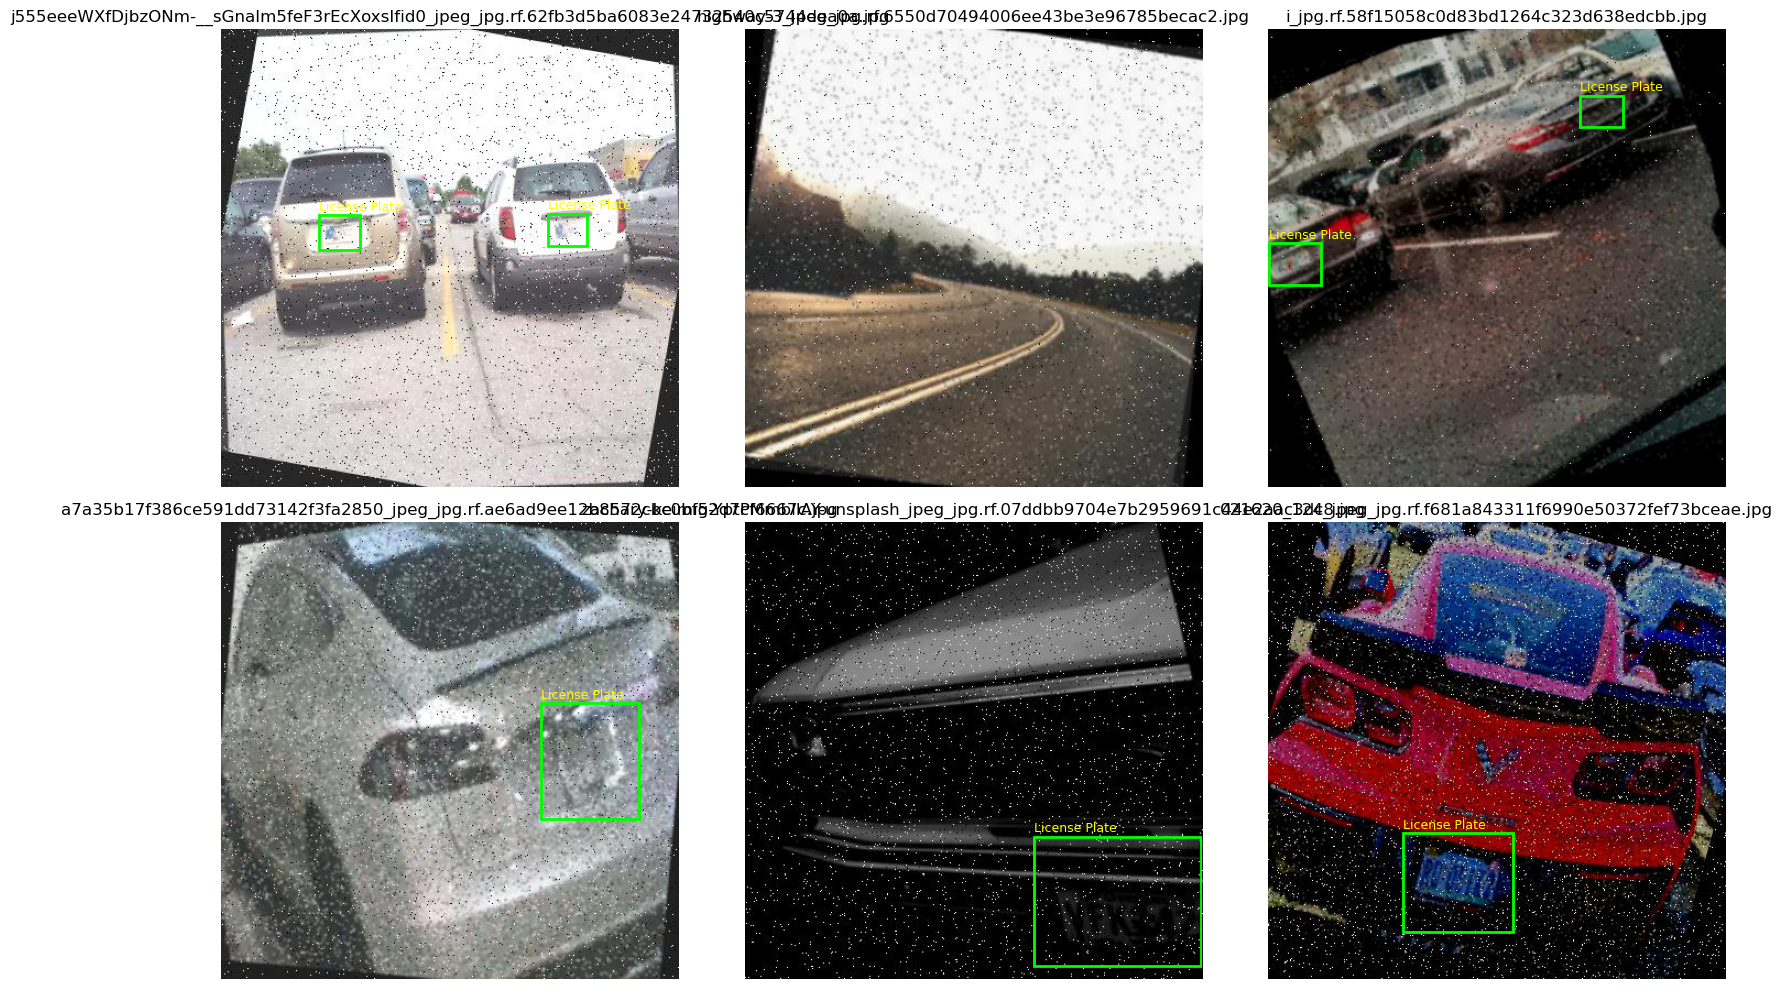

In [14]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

dataset_path = "plate_dataset"

# Random training images
image_folder = os.path.join(dataset_path, "train", "images")
label_folder = os.path.join(dataset_path, "train", "labels")

images = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

sample_images = random.sample(images, min(6, len(images)))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, image_name in zip(axes, sample_images):

    image_path = os.path.join(image_folder, image_name)
    label_path = os.path.join(
        label_folder,
        os.path.splitext(image_name)[0] + ".txt"
    )

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    ax.imshow(image)

    if os.path.exists(label_path):

        with open(label_path, "r") as file:

            for line in file:

                values = line.strip().split()

                if len(values) != 5:
                    continue

                class_id, xc, yc, bw, bh = map(float, values)

                x = (xc - bw / 2) * width
                y = (yc - bh / 2) * height

                box_width = bw * width
                box_height = bh * height

                rect = patches.Rectangle(
                    (x, y),
                    box_width,
                    box_height,
                    linewidth=2,
                    edgecolor="lime",
                    facecolor="none"
                )

                ax.add_patch(rect)

                ax.text(
                    x, max(0, y - 5),
                    "License Plate",
                    color="yellow",
                    fontsize=9
                )

    ax.set_title(image_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

LICENSE PLATE DATASET ANALYSIS


,Dataset,Images,Annotations,Average Width,Average Height
0,TRAIN,972,1371,416.0,416.0
1,VALID,92,147,416.0,416.0
2,TEST,46,61,416.0,416.0


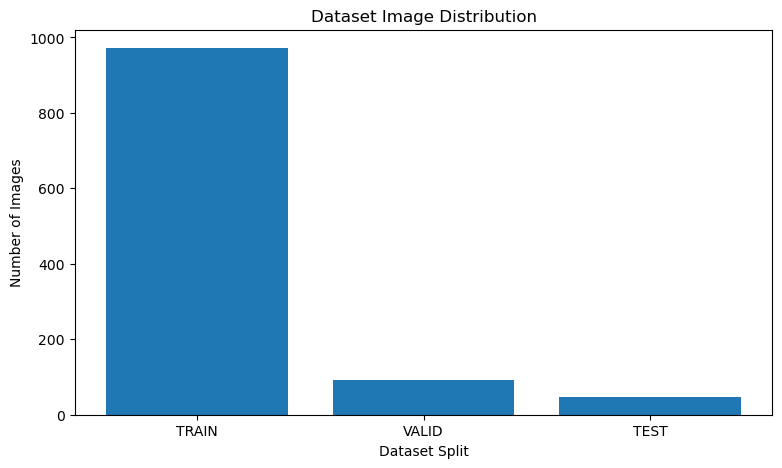

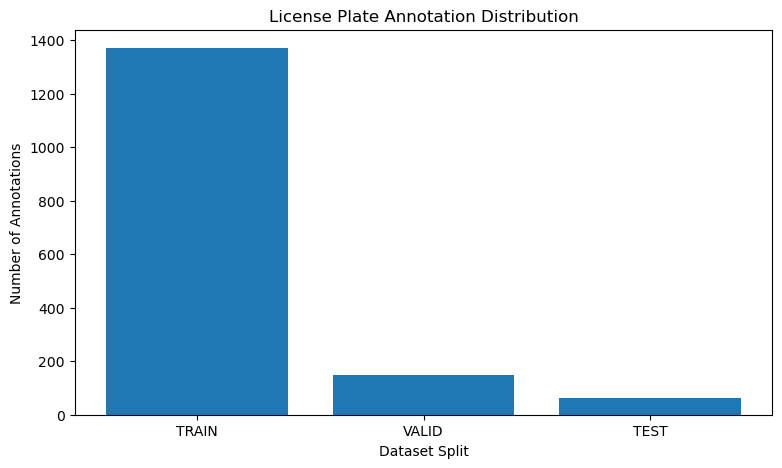

Analysis completed successfully!
CSV report saved!


In [15]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = "plate_dataset"

splits = ["train", "valid", "test"]

results = []

for split in splits:

    image_folder = os.path.join(dataset_path, split, "images")
    label_folder = os.path.join(dataset_path, split, "labels")

    image_files = glob.glob(os.path.join(image_folder, "*"))

    image_files = [
        f for f in image_files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    total_annotations = 0
    widths = []
    heights = []

    for image_path in image_files:

        img = cv2.imread(image_path)

        if img is not None:
            h, w = img.shape[:2]
            widths.append(w)
            heights.append(h)

        label_path = os.path.join(
            label_folder,
            os.path.splitext(os.path.basename(image_path))[0] + ".txt"
        )

        if os.path.exists(label_path):

            with open(label_path, "r") as file:
                total_annotations += sum(
                    1 for line in file if line.strip()
                )

    results.append({
        "Dataset": split.upper(),
        "Images": len(image_files),
        "Annotations": total_annotations,
        "Average Width": round(np.mean(widths), 2) if widths else 0,
        "Average Height": round(np.mean(heights), 2) if heights else 0
    })

df = pd.DataFrame(results)

print("LICENSE PLATE DATASET ANALYSIS")
display(df)

# Image distribution chart
plt.figure(figsize=(9, 5))
plt.bar(df["Dataset"], df["Images"])
plt.title("Dataset Image Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.show()

# Annotation distribution chart
plt.figure(figsize=(9, 5))
plt.bar(df["Dataset"], df["Annotations"])
plt.title("License Plate Annotation Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Annotations")
plt.show()

# Save report
df.to_csv("license_plate_dataset_analysis.csv", index=False)

print("Analysis completed successfully!")
print("CSV report saved!")

In [19]:
import os
import glob
import hashlib
import pandas as pd

dataset_path = "plate_dataset"

audit_results = []
hash_records = {}

for split in ["train", "valid", "test"]:

    image_folder = os.path.join(dataset_path, split, "images")
    label_folder = os.path.join(dataset_path, split, "labels")

    image_files = glob.glob(os.path.join(image_folder, "*"))

    image_files = [
        f for f in image_files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for image_path in image_files:

        filename = os.path.basename(image_path)
        label_path = os.path.join(
            label_folder,
            os.path.splitext(filename)[0] + ".txt"
        )

        issues = []

        if not os.path.exists(label_path):
            issues.append("Missing Label")
            audit_results.append({
                "Split": split,
                "Image": filename,
                "Status": " | ".join(issues)
            })
            continue

        with open(image_path, "rb") as f:
            image_hash = hashlib.md5(f.read()).hexdigest()

        if image_hash in hash_records:
            issues.append("Duplicate Image")

        hash_records[image_hash] = (split, filename)

        with open(label_path, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        if not lines:
            issues.append("Empty Label")

        for line in lines:
            try:
                values = line.split()

                if len(values) != 5:
                    raise ValueError()

                class_id, xc, yc, bw, bh = map(float, values)

                if class_id != 0:
                    issues.append("Unknown Class")

                if not (
                    0 <= xc <= 1 and
                    0 <= yc <= 1 and
                    0 < bw <= 1 and
                    0 < bh <= 1
                ):
                    issues.append("Invalid Bounding Box")

                if (
                    xc - bw / 2 < 0 or
                    yc - bh / 2 < 0 or
                    xc + bw / 2 > 1 or
                    yc + bh / 2 > 1
                ):
                    issues.append("Box Outside Image")

            except ValueError:
                issues.append("Invalid Label Format")

        audit_results.append({
            "Split": split,
            "Image": filename,
            "Status": " | ".join(sorted(set(issues))) if issues else "PASS"
        })

audit_df = pd.DataFrame(audit_results)

print("========== DATASET INTEGRITY REPORT ==========")

print("\nTotal Images Audited:", len(audit_df))
print("Passed:", (audit_df["Status"] == "PASS").sum())
print("Images With Issues:", (audit_df["Status"] != "PASS").sum())

display(audit_df.head(20))

audit_df.to_csv("license_plate_integrity_audit.csv", index=False)

print("\nAudit CSV successfully saved!")

========== DATASET INTEGRITY REPORT ==========

Total Images Audited: 1110
Passed: 1048
Images With Issues: 62


,Split,Image,Status
0,train,021620_109_jpeg_jpg.rf.1c40f4bea9911c1c6b62eac...,PASS
1,train,021620_109_jpeg_jpg.rf.477a2b8f7b8e541abb71337...,PASS
2,train,021620_109_jpeg_jpg.rf.641941ee14267ec9f5bce1c...,PASS
3,train,021620_109_jpeg_jpg.rf.6471870dc3d13b9d8f9a66a...,PASS
4,train,021620_109_jpeg_jpg.rf.67502ac0f5c1b0ad7c67f06...,PASS
5,train,021620_109_jpeg_jpg.rf.6d9fe2aee5c3639f431781b...,PASS
6,train,021620_109_jpeg_jpg.rf.b135167c0b021324f187eed...,PASS
7,train,021620_109_jpeg_jpg.rf.c6f5aabf8a1102e179fb196...,PASS
8,train,021620_109_jpeg_jpg.rf.fafb4c204c8f6a6673feead...,PASS
9,train,021620_124_jpeg_jpg.rf.19aa7346b75355387c53250...,PASS



Audit CSV successfully saved!


TOTAL BOUNDING BOXES: 1579

CLASS DISTRIBUTION:
Class
0    1579
Name: count, dtype: int64

BOUNDING BOX STATISTICS:


,Width,Height,Area
count,1579.000000,1579.000000,1579.000000
mean,0.124332,0.101393,0.027084
std,0.128777,0.119294,0.069764
min,0.002404,0.002404,0.000017
25%,0.038462,0.026442,0.001003
50%,0.086538,0.062500,0.005201
75%,0.165865,0.127404,0.020768
max,0.997596,0.975962,0.896877


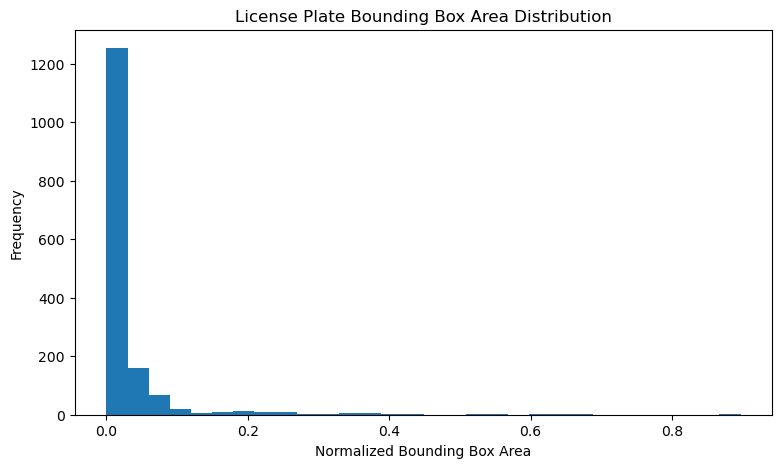

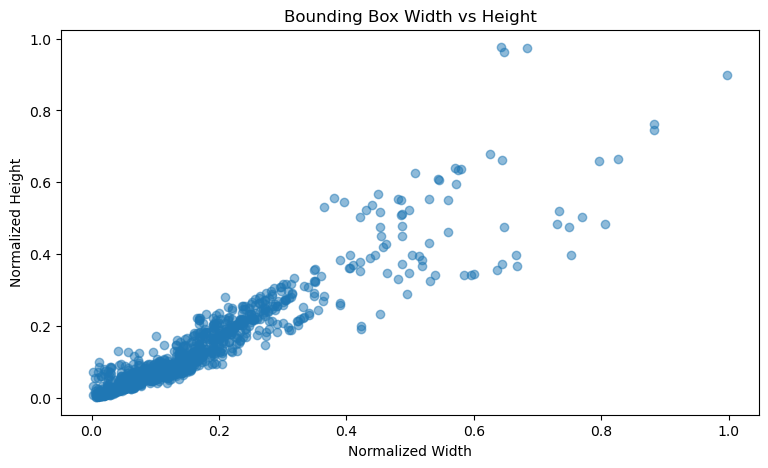

Bounding box analysis completed!


In [21]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = "plate_dataset"
splits = ["train", "valid", "test"]

box_data = []

for split in splits:

    label_folder = os.path.join(dataset_path, split, "labels")

    for file_path in glob.glob(os.path.join(label_folder, "*.txt")):

        with open(file_path, "r") as file:

            for line in file:

                values = line.strip().split()

                if len(values) != 5:
                    continue

                class_id, xc, yc, width, height = map(float, values)

                box_data.append({
                    "Split": split.upper(),
                    "Class": int(class_id),
                    "Width": width,
                    "Height": height,
                    "Area": width * height
                })

df_boxes = pd.DataFrame(box_data)

print("TOTAL BOUNDING BOXES:", len(df_boxes))
print("\nCLASS DISTRIBUTION:")
print(df_boxes["Class"].value_counts())

print("\nBOUNDING BOX STATISTICS:")
display(df_boxes[["Width", "Height", "Area"]].describe())

# Bounding box size distribution
plt.figure(figsize=(9, 5))
plt.hist(df_boxes["Area"], bins=30)
plt.title("License Plate Bounding Box Area Distribution")
plt.xlabel("Normalized Bounding Box Area")
plt.ylabel("Frequency")
plt.show()

# Width vs Height
plt.figure(figsize=(9, 5))
plt.scatter(df_boxes["Width"], df_boxes["Height"], alpha=0.5)
plt.title("Bounding Box Width vs Height")
plt.xlabel("Normalized Width")
plt.ylabel("Normalized Height")
plt.show()

df_boxes.to_csv("license_plate_bbox_statistics.csv", index=False)

print("Bounding box analysis completed!")

IMAGE QUALITY ANALYSIS


,Brightness,Contrast,Sharpness
count,1110.000000,1110.000000,1110.000000
mean,100.177964,61.848117,15573.646396
std,41.906866,10.216904,9631.638710
min,16.440000,27.360000,30.640000
25%,67.160000,54.995000,8038.672500
50%,98.305000,62.480000,14673.685000
75%,130.065000,68.747500,20658.095000
max,229.180000,97.200000,48709.200000



Average Quality By Dataset Split:


,Brightness,Contrast,Sharpness
Split,,,
TEST,88.350000,68.416739,23507.878043
TRAIN,100.790854,61.147634,14867.597706
VALID,99.616630,65.964565,19066.088478


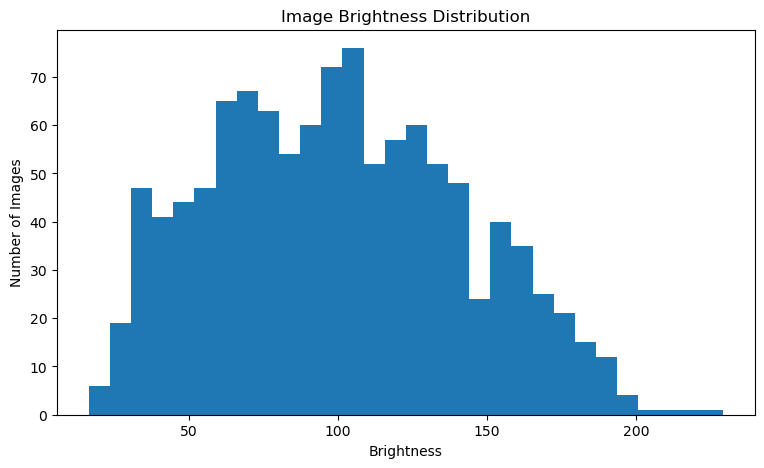

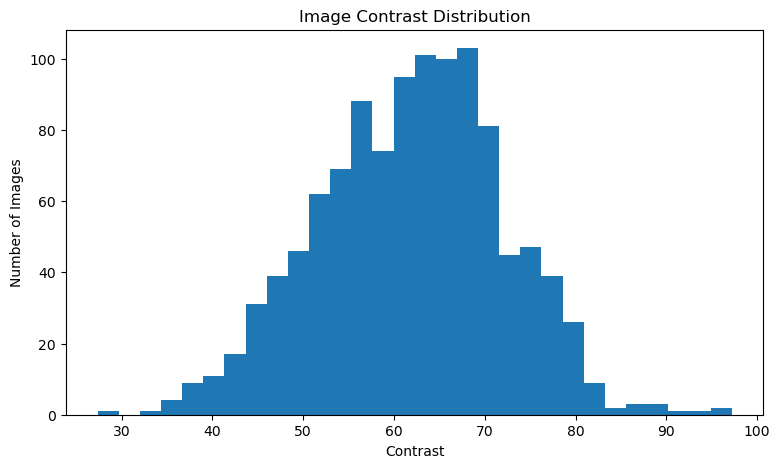

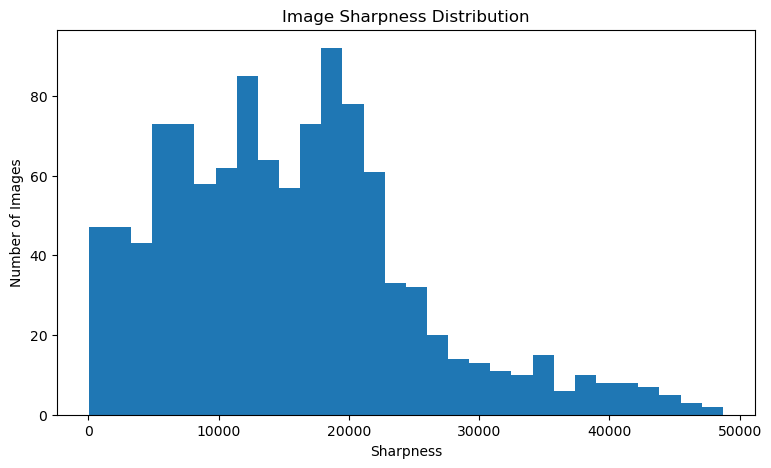

Image quality report saved successfully!


In [22]:
import os
import cv2
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset_path = "plate_dataset"

quality_results = []

for split in ["train", "valid", "test"]:

    image_folder = os.path.join(dataset_path, split, "images")

    image_files = glob.glob(os.path.join(image_folder, "*"))

    for image_path in image_files:

        image = cv2.imread(image_path)

        if image is None:
            continue

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        brightness = np.mean(gray)
        contrast = np.std(gray)
        sharpness = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        quality_results.append({
            "Split": split.upper(),
            "Image": os.path.basename(image_path),
            "Brightness": round(brightness, 2),
            "Contrast": round(contrast, 2),
            "Sharpness": round(sharpness, 2)
        })

quality_df = pd.DataFrame(quality_results)

print("IMAGE QUALITY ANALYSIS")
display(quality_df.describe())

print("\nAverage Quality By Dataset Split:")
display(
    quality_df.groupby("Split")[
        ["Brightness", "Contrast", "Sharpness"]
    ].mean()
)

# Visual analysis
for column in ["Brightness", "Contrast", "Sharpness"]:

    plt.figure(figsize=(9, 5))

    plt.hist(quality_df[column], bins=30)

    plt.title(f"Image {column} Distribution")
    plt.xlabel(column)
    plt.ylabel("Number of Images")

    plt.show()

quality_df.to_csv(
    "license_plate_image_quality.csv",
    index=False
)

print("Image quality report saved successfully!")